<a href="https://colab.research.google.com/github/Ghofranz/Fall-Detection-AI/blob/main/fall_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### 1. Import Library

In [3]:

from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile

zip_path = '/content/drive/MyDrive/Dataset/fall_dataset.zip'
extract_path = '/content/drive/MyDrive/Dataset/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset décompressé !")
print("Contenu du dossier Dataset :")
print(os.listdir(extract_path))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Dataset décompressé !
Contenu du dossier Dataset :
['fall_dataset.zip', 'fall_dataset']


In [4]:
!pip install seaborn opencv-python

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, ResNet50
import tensorflow.keras.backend as K
import gc

#### 2. Dataset Path

In [7]:
dataset_path = "/content/drive/MyDrive/Dataset/fall_dataset"

#### 3. LOAD DATASET

In [8]:
def load_dataset():
    images = []
    labels = []

    image_dir = os.path.join(dataset_path, "images", "train")
    label_dir = os.path.join(dataset_path, "labels", "train")

    size = (256, 256)

    for file in os.listdir(image_dir):
        img_path = os.path.join(image_dir, file)
        img = cv2.imread(img_path)

        if img is None:
            continue

        img = cv2.resize(img, size)
        images.append(img)

        label_file = file[:-4] + ".txt"
        label_path = os.path.join(label_dir, label_file)

        if not os.path.exists(label_path):
            continue

        with open(label_path, "r") as f:
            line = f.readline().strip().split()
            if len(line) == 0:
                continue

            label = int(float(line[0]))

            if label == 2:
                label = 1

            labels.append(label)

    return np.array(images), np.array(labels)


images, labels = load_dataset()

print("Images:", images.shape)
print("Labels:", labels.shape)

Images: (374, 256, 256, 3)
Labels: (374,)


#### 4. Preprocess data

In [9]:
def preprocess(images, labels):
    X_train, X_test, y_train, y_test = train_test_split(
        images, labels,
        test_size=0.2,
        random_state=42,
        stratify=labels
    )

    X_train = X_train.astype("float32") / 255.0
    X_test = X_test.astype("float32") / 255.0

    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = preprocess(images, labels)

#### 5. Data Augumentation

In [10]:
data_augmentor = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

data_augmentor.fit(X_train)

#### 6. MEMORY CLEAN FUNCTION

In [11]:
def clear_memory():
    K.clear_session()
    gc.collect()

#### 7. TRAINING FUNCTION

In [12]:
def train_model(model, name):
    print(f"\n===== Training {name} =====\n")

    history = model.fit(
        data_augmentor.flow(X_train, y_train, batch_size=32),
        validation_data=(X_test, y_test),
        epochs=30,
        verbose=1
    )

    preds = (model.predict(X_test) > 0.5).astype(int)

    print(f"\n{name} Classification Report")
    print(classification_report(y_test, preds))

    cm = confusion_matrix(y_test, preds)

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return model

#### 8. Model Ctreation

In [13]:
input_shape = X_train[0].shape
num_classes = 1 # For binary classification

##### 8.1. Custom CNN

In [14]:
def create_fall_detection_cnn(input_shape):
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid') # Binary classification output
    ])

    model.compile(optimizer=Adam(1e-4), # Kept original optimizer
                  loss='binary_crossentropy', # Binary classification loss
                  metrics=['accuracy'])
    return model

# Create the model and print summary
cnn_model = create_fall_detection_cnn(input_shape)
cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,839,105 (56.61 MB)

 Trainable params: 14,839,105 (56.61 MB)

 Non-trainable params: 0 (0.00 B)

##### 8.2. MobileNetV2

In [15]:
def create_mobilenet_model(input_shape):
    base = MobileNetV2(weights="imagenet", include_top=False, input_shape=input_shape)
    base.trainable = False

    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(optimizer=Adam(1e-4),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

# Create the model and print summary
mobilenet_model = create_mobilenet_model(input_shape)
mobilenet_model.summary()

/tmp/ipykernel_754/4065936857.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = MobileNetV2(weights="imagenet", include_top=False, input_shape=input_shape)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 8, 8, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

##### 8.3. EfficientNetB0

In [16]:
def create_efficientnet_model(input_shape):
    base = EfficientNetB0(weights="imagenet", include_top=False, input_shape=input_shape)
    base.trainable = True

    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(optimizer=Adam(1e-4),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

# Create the model and print summary
efficientnet_model = create_efficientnet_model(input_shape)
efficientnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 8, 8, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 4,171,645 (15.91 MB)

 Non-trainable params: 42,023 (164.16 KB)

##### 8.4. ResNet50

In [17]:
def create_resnet_model(input_shape):
    base = ResNet50(weights="imagenet", include_top=False, input_shape=input_shape)
    base.trainable = False

    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(optimizer=Adam(1e-4),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

# Create the model and print summary
resnet_model = create_resnet_model(input_shape)
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

#### 9. Train Models

##### 9.1. CNN


===== Training Custom CNN =====

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 56s 5s/step - accuracy: 0.5217 - loss: 0.7111 - val_accuracy: 0.5600 - val_loss: 0.7089
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 76s 5s/step - accuracy: 0.5585 - loss: 0.7037 - val_accuracy: 0.4933 - val_loss: 0.6890
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 48s 5s/step - accuracy: 0.5786 - loss: 0.6848 - val_accuracy: 0.5600 - val_loss: 0.6860
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 82s 5s/step - accuracy: 0.5819 - loss: 0.6885 - val_accuracy: 0.5600 - val_loss: 0.6807
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 48s 5s/step - accuracy: 0.5853 - loss: 0.6843 - val_accuracy: 0.6400 - val_loss: 0.6721
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 48s 5s/step - accuracy: 0.5652 - loss: 0.6820 - val_accuracy: 0.6533 - val_loss: 0.6610
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 51s 5s/step - accuracy: 0.6020 - loss: 0.6601 - val_accuracy: 0.7333 - val_loss: 0.6470
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 48s 5s/step - accuracy: 0.6355 - loss: 0.6448 

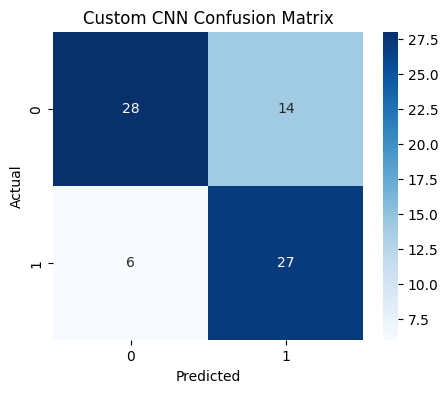

In [18]:
model = create_fall_detection_cnn(input_shape)
model = train_model(model, "Custom CNN")
model.save(os.path.join(dataset_path, "cnn_model.h5"))

clear_memory()

##### 9.2. MobileNet RUN

/tmp/ipykernel_754/4065936857.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = MobileNetV2(weights="imagenet", include_top=False, input_shape=input_shape)



===== Training MobileNetV2 =====

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step - accuracy: 0.5151 - loss: 0.7638 - val_accuracy: 0.6133 - val_loss: 0.6737
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.6187 - loss: 0.6396 - val_accuracy: 0.6667 - val_loss: 0.6151
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - accuracy: 0.6421 - loss: 0.6188 - val_accuracy: 0.6667 - val_loss: 0.5799
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.7224 - loss: 0.5457 - val_accuracy: 0.7200 - val_loss: 0.5425
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step - accuracy: 0.7458 - loss: 0.5328 - val_accuracy: 0.7600 - val_loss: 0.5147
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - accuracy: 0.7960 - loss: 0.4865 - val_accuracy: 0.8000 - val_loss: 0.4906
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.8027 - loss: 0.4617 - val_accuracy: 0.8000 - val_loss: 0.4678
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.8227 - loss: 0.4434

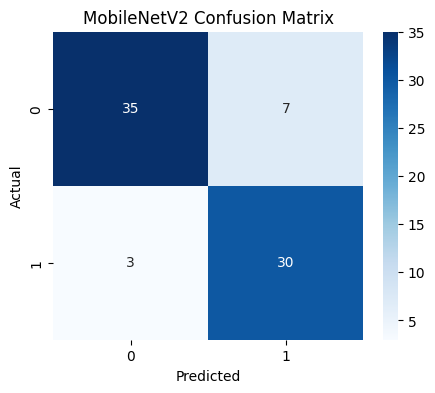

In [19]:
model = create_mobilenet_model(input_shape)
model = train_model(model, "MobileNetV2")
model.save(os.path.join(dataset_path, "mobilenet_model.h5"))

clear_memory()

##### 9.3. EfficientNet RUN


===== Training EfficientNetB0 =====

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 187s 15s/step - accuracy: 0.6020 - loss: 0.6733 - val_accuracy: 0.5600 - val_loss: 0.7001
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 145s 14s/step - accuracy: 0.7692 - loss: 0.5684 - val_accuracy: 0.5600 - val_loss: 0.7099
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 144s 14s/step - accuracy: 0.8227 - loss: 0.4825 - val_accuracy: 0.5600 - val_loss: 0.7151
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 148s 15s/step - accuracy: 0.8729 - loss: 0.3903 - val_accuracy: 0.5600 - val_loss: 0.7133
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 198s 14s/step - accuracy: 0.8829 - loss: 0.3470 - val_accuracy: 0.5600 - val_loss: 0.7054
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 147s 15s/step - accuracy: 0.9264 - loss: 0.2652 - val_accuracy: 0.5600 - val_loss: 0.7005
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 150s 16s/step - accuracy: 0.9465 - loss: 0.1773 - val_accuracy: 0.5600 - val_loss: 0.6932
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 148s 15s/step - accuracy: 0.

2/3 ━━━━━━━━━━━━━━━━━━━━ 2s 3s/step 

3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 3s/step

EfficientNetB0 Classification Report
              precision    recall  f1-score   support

           0       0.51      0.52      0.52        42
           1       0.38      0.36      0.37        33

    accuracy                           0.45        75
   macro avg       0.44      0.44      0.44        75
weighted avg       0.45      0.45      0.45        75



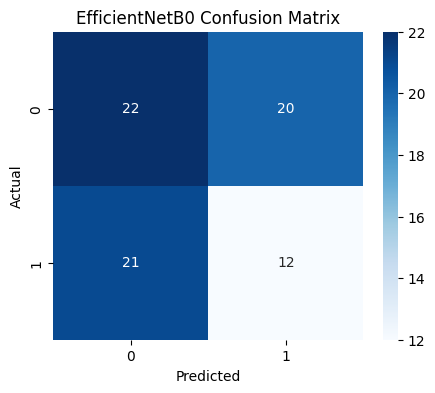

In [20]:
model = create_efficientnet_model(input_shape)
model = train_model(model, "EfficientNetB0")
model.save(os.path.join(dataset_path, "efficientnet_model.h5"))

clear_memory()

##### 9.4. ResNet


===== Training ResNet50 =====

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 94s 9s/step - accuracy: 0.4883 - loss: 0.7827 - val_accuracy: 0.5600 - val_loss: 0.6948
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 86s 9s/step - accuracy: 0.5084 - loss: 0.7409 - val_accuracy: 0.5467 - val_loss: 0.6828
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 90s 9s/step - accuracy: 0.5518 - loss: 0.7154 - val_accuracy: 0.5467 - val_loss: 0.6794
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 92s 9s/step - accuracy: 0.4950 - loss: 0.7426 - val_accuracy: 0.5600 - val_loss: 0.6756
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 88s 9s/step - accuracy: 0.5084 - loss: 0.7474 - val_accuracy: 0.5600 - val_loss: 0.6714
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 91s 9s/step - accuracy: 0.5418 - loss: 0.7177 - val_accuracy: 0.5600 - val_loss: 0.6692
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 86s 9s/step - accuracy: 0.5351 - loss: 0.7046 - val_accuracy: 0.6133 - val_loss: 0.6683
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 86s 9s/step - accuracy: 0.5184 - loss: 0.7179 - 

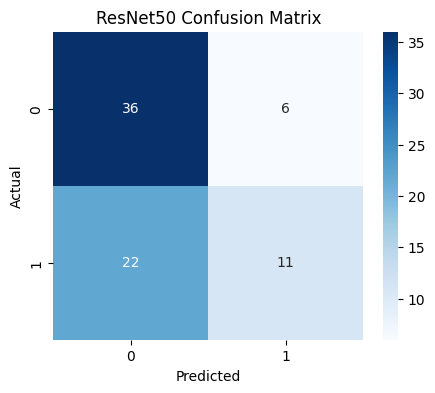

In [21]:
model = create_resnet_model(input_shape)
model = train_model(model, "ResNet50")
model.save(os.path.join(dataset_path, "resnet_model.h5"))

clear_memory()

#### 10. Model Comparison

In [22]:
from tensorflow.keras.models import load_model

models = {
    "CNN": load_model(os.path.join(dataset_path, "cnn_model.h5")),
    "MobileNetV2": load_model(os.path.join(dataset_path, "mobilenet_model.h5")),
    "EfficientNetB0": load_model(os.path.join(dataset_path, "efficientnet_model.h5")),
    "ResNet50": load_model(os.path.join(dataset_path, "resnet_model.h5"))
}

results = {}

for name, model in models.items():
    preds = (model.predict(X_test) > 0.5).astype(int)
    acc = accuracy_score(y_test, preds)
    results[name] = acc

print("\n===== FINAL MODEL COMPARISON =====")
for k, v in sorted(results.items(), key=lambda x: x[1], reverse=True):
    print(f"{k}: {v:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 738ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 4s/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 19s 6s/step

===== FINAL MODEL COMPARISON =====
MobileNetV2: 0.8667
CNN: 0.7333
ResNet50: 0.6267
EfficientNetB0: 0.5600


/tmp/ipykernel_754/3228771742.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(results.keys()), y=list(results.values()), palette='viridis')


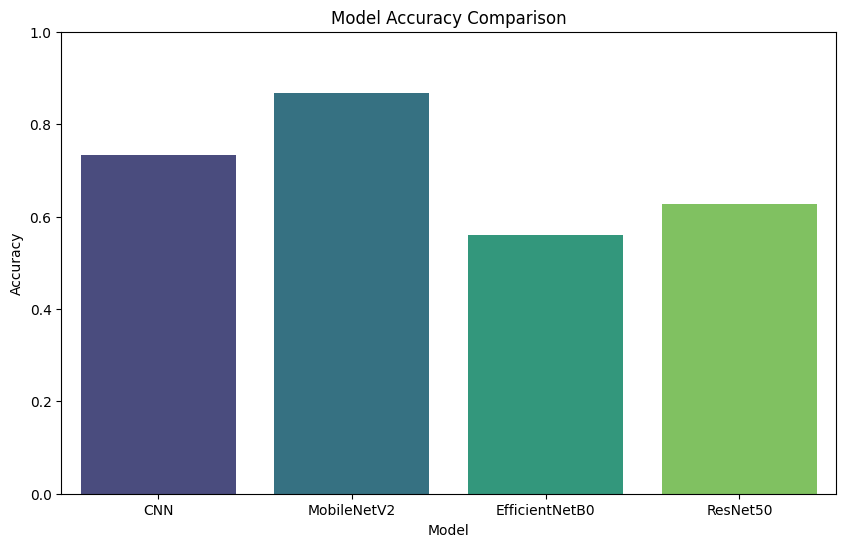

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x=list(results.keys()), y=list(results.values()), palette='viridis')
plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1) # Accuracy is between 0 and 1
plt.show()

#### 11. Save Best Model

In [24]:
best_model_name = max(results, key=results.get)
print("Best Model:", best_model_name)

Best Model: MobileNetV2


In [25]:

import numpy as np

print("Labels présents dans le dataset :")
print(np.unique(labels, return_counts=True))


Labels présents dans le dataset :
(array([0, 1]), array([207, 167]))


In [26]:

!pip -q install gradio

import gradio as gr
import cv2
import numpy as np
import tensorflow as tf

# Charger ton modèle déjà entraîné
model_path = "/content/drive/MyDrive/Dataset/fall_dataset/mobilenet_model.h5"

from google.colab import drive
drive.mount("/content/drive")

model = tf.keras.models.load_model(model_path, compile=False)

def detect_fall(image):
    # Même prétraitement que dans l'application d'origine
    frame = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    frame = cv2.resize(frame, (256, 256))
    frame = frame.astype("float32") / 255.0
    frame = np.expand_dims(frame, axis=0)

    prediction = model.predict(frame, verbose=0)[0][0]
    probability_fall = 1 - float(prediction)

    if probability_fall >= 0.5:
        return f"🚨 FALL DETECTED — {probability_fall:.2%}"
    else:
        return f"✅ NO FALL — {1 - probability_fall:.2%}"

demo = gr.Interface(
    fn=detect_fall,
    inputs=gr.Image(type="numpy", label="Upload Image"),
    outputs=gr.Textbox(label="Prediction"),
    title="Elderly Fall Detection AI",
    description="Fall Detection using your trained MobileNetV2 model"
)

demo.launch(share=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dce4f0a82f39db70d3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [33]:

import gradio as gr
import cv2
import numpy as np
import tensorflow as tf
import tempfile
import os
import subprocess
from collections import deque
from google.colab import drive

# ==========================================================
# 1. CHARGEMENT DU MODELE
# ==========================================================

drive.mount("/content/drive")

MODEL_PATH = (
    "/content/drive/MyDrive/Dataset/"
    "fall_dataset/mobilenet_model.h5"
)

model_video = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("MobileNetV2 charge avec succes !")


# ==========================================================
# 2. ANALYSE VIDEO
# ==========================================================

def analyze_video(video_path):

    if video_path is None:
        raise gr.Error("Veuillez importer une video MP4.")

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise gr.Error("Impossible de lire la video.")

    fps = cap.get(cv2.CAP_PROP_FPS)

    if not np.isfinite(fps) or fps <= 0:
        fps = 25.0

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    frames = []
    scores = []

    # ------------------------------------------------------
    # A. Analyse de toutes les images
    # ------------------------------------------------------

    while True:
        ok, frame = cap.read()

        if not ok:
            break

        # Meme preparation que pendant l'entrainement :
        # BGR, 256x256, normalisation /255
        image = cv2.resize(frame, (256, 256))
        image = image.astype(np.float32) / 255.0
        image = np.expand_dims(image, axis=0)

        prediction = float(
            model_video.predict(
                image, verbose=0
            )[0][0]
        )

        fall_score = 1.0 - prediction

        frames.append(frame)
        scores.append(fall_score)

    cap.release()

    if len(frames) == 0:
        raise gr.Error("Aucune image lisible dans la video.")

    # ------------------------------------------------------
    # B. Detection temporelle experimentale
    # ------------------------------------------------------

    window = max(1, round(fps * 2))
    history = deque(maxlen=window + 1)

    alerts = []
    direct_alerts = []
    temporal_alerts = []

    first_alert = None

    for i, score in enumerate(scores):

        previous_min = (
            min(history) if history else score
        )

        increase = score - previous_min

        # Classification directe MobileNetV2
        direct_detection = score >= 0.50

        # Regle temporelle experimentale
        temporal_detection = (
            increase >= 0.25
            and score >= 0.30
        )

        alert = (
            direct_detection or temporal_detection
        )

        direct_alerts.append(direct_detection)
        temporal_alerts.append(temporal_detection)
        alerts.append(alert)

        if alert and first_alert is None:
            first_alert = i / fps

        history.append(score)

    # ------------------------------------------------------
    # C. Creation de la video annotee
    # ------------------------------------------------------

    output_dir = tempfile.mkdtemp()

    raw_path = os.path.join(
        output_dir, "raw_video.mp4"
    )

    final_path = os.path.join(
        output_dir, "fall_detection_final.mp4"
    )

    # Espace reserve exclusivement aux textes
    header_height = 145

    writer = cv2.VideoWriter(
        raw_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height + header_height)
    )

    if not writer.isOpened():
        raise gr.Error(
            "Impossible de creer la video annotee."
        )

    alert_active = False

    for i, original in enumerate(frames):

        frame = original.copy()

        if alerts[i]:
            alert_active = True

        # Couleurs BGR pour OpenCV
        if alert_active:
            color = (0, 0, 255)
            title = "ALERTE CHUTE"
            subtitle = "Alerte temporelle experimentale"
        else:
            color = (0, 190, 0)
            title = "NORMAL"
            subtitle = "Aucune alerte detectee"

        # Zone de texte SEPAREE de la video
        canvas = cv2.copyMakeBorder(
            frame,
            header_height, 0, 0, 0,
            cv2.BORDER_CONSTANT,
            value=(28, 28, 28)
        )

        # Trait coloré sous le bandeau
        cv2.line(
            canvas,
            (0, header_height - 2),
            (width, header_height - 2),
            color,
            4
        )

        # Cadre autour de l'image uniquement
        thickness = max(4, width // 140)

        cv2.rectangle(
            canvas,
            (2, header_height + 2),
            (width - 3, height + header_height - 3),
            color,
            thickness
        )

        font = cv2.FONT_HERSHEY_SIMPLEX

        def write_fitted(text, y, max_scale, color,
                         thickness=2):

            available = width - 32
            scale = max_scale

            while scale > 0.25:
                (text_width, _), _ = cv2.getTextSize(
                    text, font, scale, thickness
                )

                if text_width <= available:
                    break

                scale -= 0.05

            cv2.putText(
                canvas,
                text,
                (16, y),
                font,
                max(scale, 0.25),
                color,
                thickness,
                cv2.LINE_AA
            )

        # Grand statut : sans chevauchement
        write_fitted(
            title, 40, 1.0, color, 3
        )

        write_fitted(
            subtitle, 72, 0.65,
            (235, 235, 235), 1
        )

        write_fitted(
            f"Score FALL MobileNetV2 : "
            f"{scores[i] * 100:.1f}%",
            101, 0.65,
            (255, 255, 255), 1
        )

        if alert_active and first_alert is not None:
            info = (
                f"Premiere alerte : "
                f"{first_alert:.2f} s"
            )
        else:
            info = (
                f"Temps : {i / fps:.2f} s"
            )

        write_fitted(
            info, 129, 0.60,
            (220, 220, 220), 1
        )

        writer.write(canvas)

    writer.release()

    # ------------------------------------------------------
    # D. Conversion en MP4 lisible par navigateur
    # ------------------------------------------------------

    conversion = subprocess.run(
        [
            "ffmpeg",
            "-y",
            "-loglevel", "error",
            "-i", raw_path,
            "-c:v", "libx264",
            "-pix_fmt", "yuv420p",
            "-movflags", "+faststart",
            final_path
        ],
        capture_output=True,
        text=True
    )

    if conversion.returncode != 0:
        raise gr.Error(
            "Erreur FFmpeg : " + conversion.stderr
        )

    # ------------------------------------------------------
    # E. Rapport final
    # ------------------------------------------------------

    if first_alert is not None:
        verdict = "ALERTE CHUTE DECLENCHEE"
        alert_time = f"{first_alert:.2f} secondes"
    else:
        verdict = "AUCUNE ALERTE"
        alert_time = "Aucune"

    report = (
        f"RESULTAT : {verdict}\n\n"
        f"Premiere alerte : {alert_time}\n"
        f"Duree : {len(frames) / fps:.2f} s\n"
        f"Images analysees : {len(frames)}\n"
        f"Score FALL maximal : {max(scores):.1%}\n"
        f"Detections directes du modele : "
        f"{sum(direct_alerts)}\n"
        f"Alertes temporelles : "
        f"{sum(temporal_alerts)}\n\n"
        "Note : l'alerte temporelle est "
        "experimentale et ne confirme pas "
        "une chute a elle seule."
    )

    return final_path, report


# ==========================================================
# 3. INTERFACE GRADIO
# ==========================================================

with gr.Blocks(title="Fall Detection AI") as demo:

    gr.Markdown(
        "# Fall Detection — AI Video Demo"
    )

    gr.Markdown(
        "Analyse de videos avec MobileNetV2 et "
        "alerte temporelle experimentale."
    )

    with gr.Row():

        with gr.Column():
            input_video = gr.Video(
                label="Video originale",
                height=380
            )

            analyze_button = gr.Button(
                "ANALYSER LA VIDEO",
                variant="primary"
            )

        with gr.Column():
            output_video = gr.Video(
                label="",
                show_label=False,
                height=380
            )

            output_report = gr.Textbox(
                label="Rapport d'analyse",
                lines=10,
                interactive=False
            )

    analyze_button.click(
        fn=analyze_video,
        inputs=input_video,
        outputs=[
            output_video,
            output_report
        ]
    )

demo.launch(share=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MobileNetV2 charge avec succes !
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d686d5f8b3860d77d0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [29]:

import cv2
import numpy as np
from google.colab import files

uploaded = files.upload()
video_path = next(iter(uploaded))

cap = cv2.VideoCapture(video_path)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.set(cv2.CAP_PROP_POS_FRAMES, total // 2)
ret, frame = cap.read()
cap.release()

if ret:
    cv2.imwrite("video_frame.jpg", frame)
    files.download("video_frame.jpg")
else:
    print("Impossible d'extraire une image.")


Saving fall_detection_test.mp4 to fall_detection_test.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

              precision    recall  f1-score   support

        Fall       0.92      0.83      0.88        42
    Non-Fall       0.81      0.91      0.86        33

    accuracy                           0.87        75
   macro avg       0.87      0.87      0.87        75
weighted avg       0.87      0.87      0.87        75



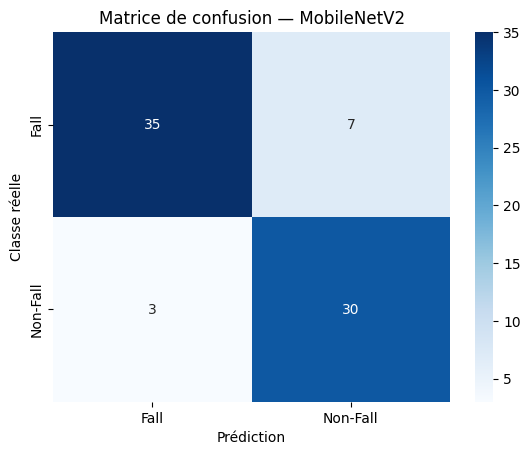

In [30]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

predictions = model.predict(X_test, verbose=0)
y_pred = (predictions.ravel() > 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fall", "Non-Fall"],
    zero_division=0
))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fall", "Non-Fall"],
    yticklabels=["Fall", "Non-Fall"]
)

plt.xlabel("Prédiction")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion — MobileNetV2")
plt.show()
